#**TRAINING**

##**Data Preprocessing**

In [1]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/CHALLENGE1ANN"
%cd $current_dir

Mounted at /gdrive
/gdrive/.shortcut-targets-by-id/1zXlKtIs_l7uErhQ5LyiPQwfRNFrTdsfW/CHALLENGE1ANN


In [2]:
# Set seed for reproducibility
SEED = 50

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


In [3]:
X_train = pd.read_csv('pirate_pain_train.csv')
y_train = pd.read_csv('pirate_pain_train_labels.csv')
X_test = pd.read_csv('pirate_pain_test.csv')

In [4]:
# since the feature joint_30 is the same value for every sample (0.5) we elimnate it
X_train = X_train.drop('joint_30', axis=1)
X_test = X_test.drop('joint_30', axis=1)

In [5]:
#Change the datatype of joint columns to float32
# Loop for the joint columns
for i in range(30):
    col_name = f'joint_{i:02d}' # Formatting the column name (es. 'joint_00', 'joint_01')
    if col_name in X_train.columns:
        X_train[col_name] = X_train[col_name].astype(np.float32)
        X_test[col_name] = X_test[col_name].astype(np.float32)

print("Verifying data types after conversion using for loop:")
X_train.info()

#the dataset doesn't seem to have any missing values

Verifying data types after conversion using for loop:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 39 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float32
 10  joint_01       105760 non-null  float32
 11  joint_02       105760 non-null  float32
 12  joint_03       105760 non-null  float32
 13  joint_04       105760 non-null  float32
 14  joint_05       105760 non-null  float32
 15  joint_06       105760 non-null  float32
 16  joint_07       10576

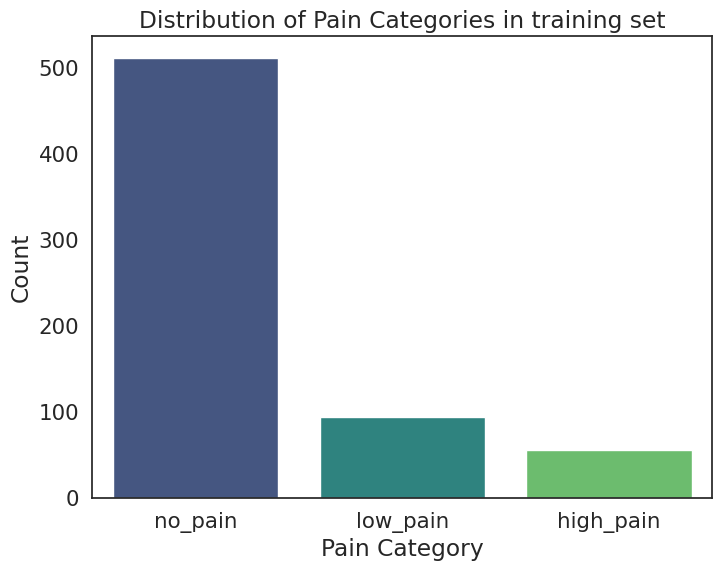

In [ ]:
# data distribution before augmentation
plt.figure(figsize=(8, 6))
sns.countplot(data=y_train, x='label', palette='viridis')
plt.title('Distribution of Pain Categories in training set')
plt.xlabel('Pain Category')
plt.ylabel('Count')
plt.show()

In [6]:
columns_to_analyze = ['n_legs', 'n_hands', 'n_eyes']

for col in columns_to_analyze:
    print(f"\nUnique values and counts for column: {col}")
    print(X_train[col].value_counts())


Unique values and counts for column: n_legs
n_legs
two            104800
one+peg_leg       960
Name: count, dtype: int64

Unique values and counts for column: n_hands
n_hands
two              104800
one+hook_hand       960
Name: count, dtype: int64

Unique values and counts for column: n_eyes
n_eyes
two              104800
one+eye_patch       960
Name: count, dtype: int64


In [7]:
# Define a mapping of n_legs values to integer labels
label_mapping_legs = {
    'two': 0,
    'one+peg_leg': 1,
}
# Map n_legs attributes to integers in the training set
X_train['n_legs'] = X_train['n_legs'].map(label_mapping_legs)
X_test['n_legs'] = X_test['n_legs'].map(label_mapping_legs)

# Define a mapping of n_hands values to integer labels
label_mapping_hands = {
    'two': 0,
    'one+hook_hand': 1,
}
# Map n_hands attributes to integers in the training set
X_train['n_hands'] = X_train['n_hands'].map(label_mapping_hands)
X_test['n_hands'] = X_test['n_hands'].map(label_mapping_hands)

# Define a mapping of n_eyes values to integer labels
label_mapping_eyes = {
    'two': 0,
    'one+eye_patch': 1,
}
# Map n_eyes attributes to integers in the training set
X_train['n_eyes'] = X_train['n_eyes'].map(label_mapping_eyes)
X_test['n_eyes'] = X_test['n_eyes'].map(label_mapping_eyes)

In [8]:
#expand the original y_train dataset in order to have the label for every timestamp of each sample_index
y_train_expanded = y_train.loc[y_train.index.repeat(160)].reset_index(drop=True)
print(f"Original y_train shape: {y_train.shape}")
print(f"Expanded y_train shape: {y_train_expanded.shape}")

Original y_train shape: (661, 2)
Expanded y_train shape: (105760, 2)


In [9]:
#add the label to the X_train dataset
X_train_mod = X_train.copy()
X_train_mod['label'] = y_train_expanded['label']

In [10]:
# Get unique user IDs and shuffle them
unique_users = X_train_mod['sample_index'].unique()
random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)

# Define the number of users for validation set
N_VAL_USERS = 75 # You can change this number

# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:n_train_users + N_VAL_USERS]

# Split the dataset into training, validation, and test sets based on user IDs
df_train = X_train_mod[X_train_mod['sample_index'].isin(train_users)]
df_val = X_train_mod[X_train_mod['sample_index'].isin(val_users)]

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')

Training set shape: (93760, 40)
Validation set shape: (12000, 40)


In [11]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 455, 'low_pain': 82, 'high_pain': 49}


In [12]:
# Initialise a dictionary to count occurrences of each activity in the validation set
val_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of training labels
print('Validation labels:', val_labels)


Validation labels: {'no_pain': 56, 'low_pain': 12, 'high_pain': 7}


In [13]:
# Define a mapping of pain values to integer labels
label_mapping_pain = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2,
}

# Map activity pain levels to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping_pain)

# Map activity pain levels to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping_pain)

In [14]:
# Define the columns to be normalised
scale_columns = []
for i in range(30):
    scale_columns.append(f'joint_{i:02d}') # Formatting the column name (es. 'joint_00', 'joint_01')

# Calculate the minimum and maximum values from the training data only
# we normalize with respect to the training set, as we have always done
#this is min-max scaling
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the training set
    df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the validation set
    df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the test set
    X_test[column] = (X_test[column] - mins[column]) / (maxs[column] - mins[column])

In [15]:
###########################################
WINDOW_SIZE = 30
STRIDE = 5
###########################################

In [16]:
# Define a function to build sequences from the dataset
def build_sequences(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]


    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Retrieve the activity label for the current ID
        label = df[df['sample_index'] == id]['label'].values[0]

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))


        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [17]:
# Define a function to build sequences from the dataset
def build_sequences_test(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            idx += stride

    # Convert lists to numpy arrays for further processing
    # dataset = np.array(dataset)

    return dataset

In [18]:
# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences for the test set
X_test_windowed = build_sequences_test(X_test, WINDOW_SIZE, STRIDE)


# Print the shapes of the generated datasets and their labels
print(f"Training sequences shape: {X_train.shape}, Labels shape: {y_train.shape}")
print(f"Validation sequences shape: {X_val.shape}, Labels shape: {y_val.shape}")
print(f"Test sequences shape: {np.array(X_test_windowed).shape}")

# Data augmentation using tsaug
!pip install tsaug
from tsaug import TimeWarp, Crop, Quantize, Drift

# Assuming X_train and y_train are already windowed NumPy arrays

def augment_time_series(X_data, y_data, augment_classes, num_augments_per_class):
    augmented_X = []
    augmented_y = []

    # Define the augmentation pipeline
    # Removed Crop to maintain consistent sequence length (WINDOW_SIZE)
    augmenter = (
        TimeWarp(n_speed_change=4, max_speed_ratio=3, seed=SEED) \
        + Drift(max_drift=(0.05), seed=SEED)
    )

    for class_label in augment_classes:
        # Select samples belonging to the current minority class
        minority_indices = np.where(y_data == class_label)[0]
        X_minority = X_data[minority_indices]
        y_minority = y_data[minority_indices]

        # Augment each sample in the minority class
        for i in range(X_minority.shape[0]):
            original_sample = X_minority[i]
            # tsaug expects (num_samples, num_timesteps, num_features)
            # We augment one sample at a time, so num_samples=1
            augmented_samples = augmenter.augment(original_sample[np.newaxis, :, :])

            # Dynamically set the number of augmentations per sample based on its class
            num_augments = num_augments_per_class.get(class_label, 1)

            # Repeat the augmentation 'num_augments' times for each original sample
            for _ in range(num_augments):
                augmented_X.append(augmented_samples[0]) # Take the first (and only) augmented sample
                augmented_y.append(class_label)

    if augmented_X:
        augmented_X = np.array(augmented_X, dtype=X_data.dtype)
        augmented_y = np.array(augmented_y, dtype=y_data.dtype)
        print(f"Shape of augmented X: {augmented_X.shape}")
        print(f"Shape of augmented y: {augmented_y.shape}")

        # Concatenate augmented data with original data
        X_augmented = np.concatenate((X_data, augmented_X), axis=0)
        y_augmented = np.concatenate((y_data, augmented_y), axis=0)
    else:
        X_augmented = X_data
        y_augmented = y_data

    return X_augmented, y_augmented

# Identify minority classes (assuming integer labels 0: no_pain, 1: low_pain, 2: high_pain)
# Based on `training_labels`: 'no_pain': 455, 'low_pain': 82, 'high_pain': 49
# The label mapping happens later so X_train and y_train have string labels from df_train. I need to make sure this is handled correctly.
# Looking at the code for build_sequences, y_train becomes numeric labels AFTER the label_mapping_pain is applied to df_train. Therefore, the y_train in this cell should already be numeric.
# So the y_train from build_sequences will indeed be integer labels.
minority_classes_for_augmentation = [1, 2] # low_pain (1) and high_pain (2)

# Define the number of augmentations for each minority class
# Augment 'low_pain' 4 times and 'high_pain' 5 times
num_augments_per_class_dict = {1: 4, 2: 6}

# Apply augmentation to training data
X_train, y_train = augment_time_series(
    X_train, y_train,
    augment_classes=minority_classes_for_augmentation,
    num_augments_per_class=num_augments_per_class_dict
)

print(f"Final X_train shape after augmentation: {X_train.shape}")
print(f"Final y_train shape after augmentation: {y_train.shape}")

# Verify label distribution after augmentation
augmented_label_counts = pd.Series(y_train).value_counts().sort_index()
print("\nLabel distribution after augmentation:")
print(augmented_label_counts)

Training sequences shape: (18166, 30, 37), Labels shape: (18166,)
Validation sequences shape: (2325, 30, 37), Labels shape: (2325,)
Test sequences shape: (41044, 30, 37)
Shape of augmented X: (19282, 30, 37)
Shape of augmented y: (19282,)
Final X_train shape after augmentation: (37448, 30, 37)
Final y_train shape after augmentation: (37448,)

Label distribution after augmentation:
0    14105
1    12710
2    10633
Name: count, dtype: int64


In [19]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [20]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

In [21]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 128

In [22]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [23]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [24]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([128, 30, 37])
Labels batch shape: torch.Size([128])


##**Model Building**

In [25]:
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [26]:
# Training configuration
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 70

# Architecture
HIDDEN_LAYERS = 3        # Hidden layers
HIDDEN_SIZE = 64          # Neurons per layer

# Regularisation
DROPOUT_RATE = 0.5       # Dropout probability
L1_LAMBDA = 0            # L1 penalty
L2_LAMBDA = 1e-4         # L2 penalty

# Set up loss function and optimizer
criterion = nn.CrossEntropyLoss()

In [27]:
class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,   # the model works forward and backward
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)  # RNN already have non-linearities implemented

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # Ensure input to RNN is float32 for compatibility
        x = x.to(torch.float32)

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x) # rnn_out and hidden are the same

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        if self.bidirectional:
            # Reshape to (num_layers, 2, batch_size, hidden_size)
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)

            # Concat last fwd (hidden[-1, 0, ...]) and bwd (hidden[-1, 1, ...])
            # Final shape: (batch_size, hidden_size * 2)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            # Take the last layer's hidden state
            # Final shape: (batch_size, hidden_size)
            hidden_to_classify = hidden[-1]

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits

##**Model Training**

In [28]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [29]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            # Cast input to float16 for mixed precision training
            inputs = inputs.to(torch.float16)
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [30]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                inputs = inputs.to(torch.float16) # Add this line
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [31]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [32]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0
        model_save_path = os.path.join("models", experiment_name + '_model.pt')


    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), model_save_path)
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(model_save_path))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        model_save_path = os.path.join("models", experiment_name + '_model.pt')
        torch.save(model.state_dict(), model_save_path)
        print(f"Saved final model to {model_save_path}")


    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [33]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=False,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name = "lstm_augmented_CONSEGNA"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(rnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 30, 64], [3, -1, 64]]  92,928         
classifier (Linear)       [-1, 3]                      195            
Total params: 93,123
Trainable params: 93,123
Non-trainable params: 0
-------------------------------------------------------------------------------


In [ ]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.7703, F1 Score=0.6286 | Val: Loss=0.5093, F1 Score=0.8586
Epoch   2/500 | Train: Loss=0.4202, F1 Score=0.8267 | Val: Loss=0.3852, F1 Score=0.8603
Epoch   3/500 | Train: Loss=0.2650, F1 Score=0.8913 | Val: Loss=0.4491, F1 Score=0.8903
Epoch   4/500 | Train: Loss=0.1940, F1 Score=0.9211 | Val: Loss=0.3718, F1 Score=0.8848
Epoch   5/500 | Train: Loss=0.1601, F1 Score=0.9340 | Val: Loss=0.4004, F1 Score=0.8747
Epoch   6/500 | Train: Loss=0.1378, F1 Score=0.9414 | Val: Loss=0.5212, F1 Score=0.8418
Epoch   7/500 | Train: Loss=0.1222, F1 Score=0.9473 | Val: Loss=0.3303, F1 Score=0.9192
Epoch   8/500 | Train: Loss=0.1101, F1 Score=0.9524 | Val: Loss=0.3316, F1 Score=0.9073
Epoch   9/500 | Train: Loss=0.1126, F1 Score=0.9511 | Val: Loss=0.3011, F1 Score=0.9175
Epoch  10/500 | Train: Loss=0.0979, F1 Score=0.9568 | Val: Loss=0.4209, F1 Score=0.8926
Epoch  11/500 | Train: Loss=0.0923, F1 Score=0.9590 | Val: Loss=0.3270, F1 Score=0.9143
Epoch  12

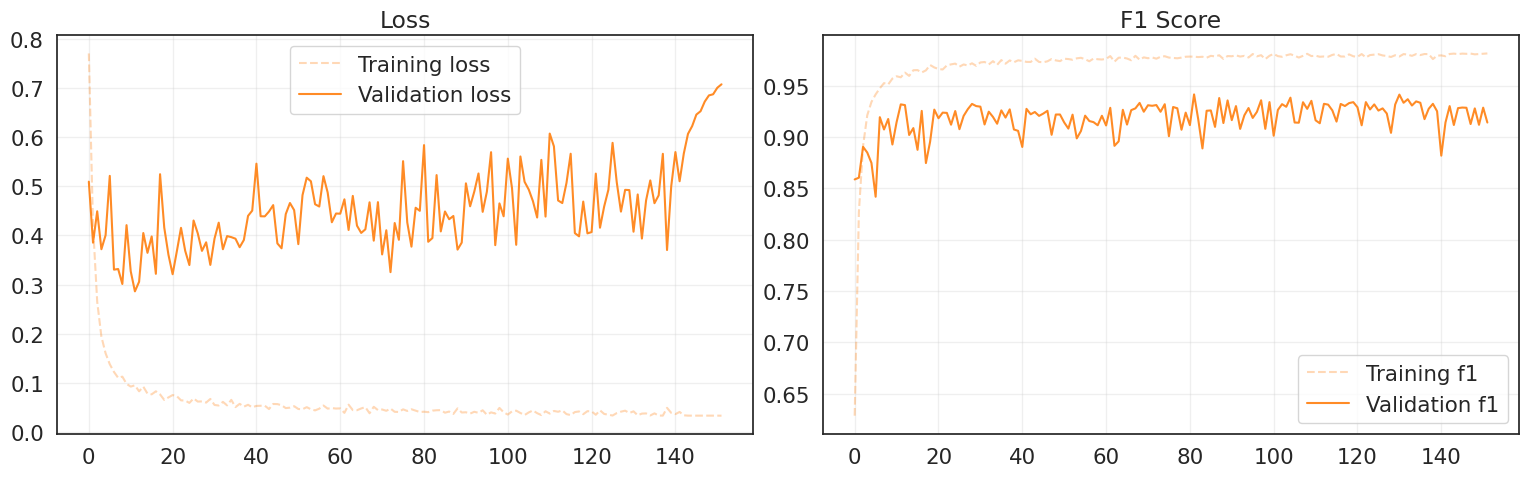

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9426
Precision over the validation set: 0.9416
Recall over the validation set: 0.9426
F1 score over the validation set: 0.9418


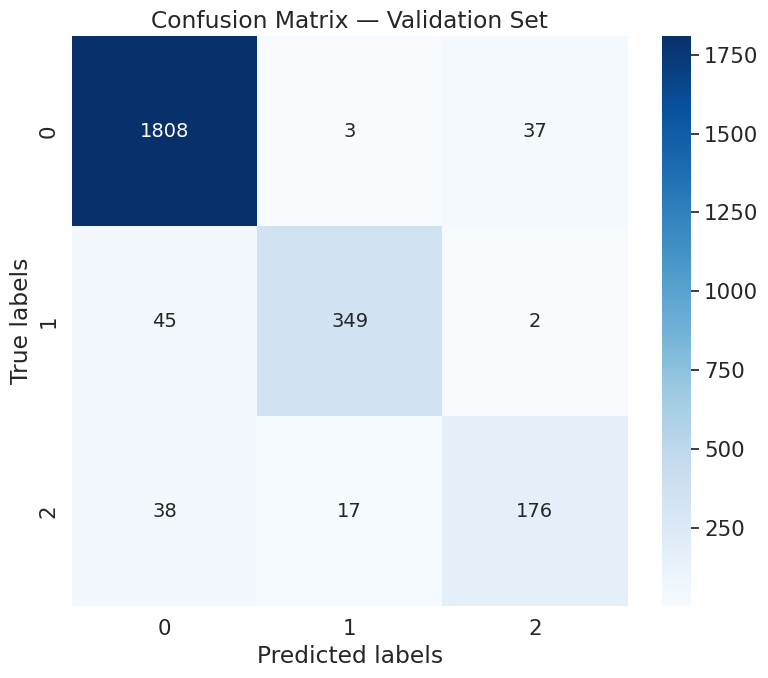

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

##**K-Shuffle-Split Cross Validation**

In [36]:
# Cross-validation
K = 5                    # Number of splits (5 and 10 are considered good values)
N_VAL_USERS = 75         # Number of users for validation split

# Training
EPOCHS = 500             # Maximum epochs (increase to improve performance)
PATIENCE = 70            # Early stopping patience (increase to improve performance)
VERBOSE = 10             # Print frequency

# Optimisation
LEARNING_RATE = 1e-3     # Learning rate
BATCH_SIZE = 128         # Batch size
WINDOW_SIZE = 20         # Input window size
STRIDE = 5               # Input stride

# Architecture
HIDDEN_LAYERS = 4        # Hidden layers
HIDDEN_SIZE = 64         # Neurons per layer
RNN_TYPE = 'LSTM'        # Type of RNN architecture
BIDIRECTIONAL = False    # Bidirectional RNN

# Regularisation
DROPOUT_RATE = 0.5       # Dropout probability
L1_LAMBDA = 0            # L1 penalty
L2_LAMBDA = 1e-4         # L2 penalty

# Training utilities
criterion = nn.CrossEntropyLoss()

In [37]:
def k_shuffle_split_cross_validation_round_rnn(df, epochs, criterion, device,
                            k, n_val_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional,
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name=""):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        epochs: Number of training epochs
        criterion: Loss function
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    in_features = 37
    num_classes = 3

    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        # Get unique user IDs and shuffle them with split-specific seed
        unique_users = X_train_mod['sample_index'].unique()
        random.seed(seed + split_idx)
        random.shuffle(unique_users)

        # Calculate the number of users for the training set
        n_train_users = len(unique_users) - n_val_users

        # Split the shuffled user IDs into training, validation
        train_users = unique_users[:n_train_users]
        val_users = unique_users[n_train_users:n_train_users + n_val_users]

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = X_train_mod[X_train_mod['sample_index'].isin(train_users)].copy()
        df_val = X_train_mod[X_train_mod['sample_index'].isin(val_users)].copy()

        # Define a mapping of activity names to integer labels
        label_mapping = {
            'no_pain': 0,
            'low_pain': 1,
            'high_pain': 2,
        }

        # Map activity names to integers in the training set
        df_train['label'] = df_train['label'].map(label_mapping)

        # Map activity names to integers in the validation set
        df_val['label'] = df_val['label'].map(label_mapping)

        if verbose > 0:
            print(f"  Training set shape: {df_train.shape}")
            print(f"  Validation set shape: {df_val.shape}")

        # Define the columns to be normalised
        scale_columns = []
        for i in range(30):
          scale_columns.append(f'joint_{i:02d}') # Formatting the column name (es. 'joint_00', 'joint_01')

        # Calculate the minimum and maximum values from the training data only
        # we normalize with respect to the training set, as we have always done
        #this is min-max scaling
        train_min = df_train[scale_columns].min()
        train_max = df_train[scale_columns].max()

        # Apply normalisation to the specified columns in all datasets
        for column in scale_columns:
            # Normalise the training set
            df_train[column] = (df_train[column] - train_min[column]) / (train_max[column] - train_min[column])

            # Normalise the validation set
            df_val[column] = (df_val[column] - train_min[column]) / (train_max[column] - train_min[column])

        # Build sequences using the existing build_sequences function
        X_train, y_train = build_sequences(df_train, window=window_size, stride=stride)
        X_val, y_val = build_sequences(df_val, window=window_size, stride=stride)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")

        # Create PyTorch datasets
        train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
        val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

        # Create data loaders
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx)
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}±{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores

In [ ]:
%%time
# Execute K-fold cross-validation with baseline configuration
losses, metrics, best_scores = k_shuffle_split_cross_validation_round_rnn(
    df=X_train_mod,
    epochs=EPOCHS,
    criterion=criterion,
    device=device,
    k=K,
    batch_size=BATCH_SIZE,
    hidden_layers=HIDDEN_LAYERS,
    hidden_size=HIDDEN_SIZE,
    learning_rate=LEARNING_RATE,
    dropout_rate=DROPOUT_RATE,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    verbose=VERBOSE,
    patience=PATIENCE,
    seed=SEED,
    experiment_name="fold_sanpancrazio",
    n_val_users=N_VAL_USERS,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
    rnn_type=RNN_TYPE,
    bidirectional=BIDIRECTIONAL
)

Split 1/5
  Training set shape: (94560, 40)
  Validation set shape: (11200, 40)
  Training sequences shape: (18321, 30, 37)
  Validation sequences shape: (2170, 30, 37)
Training 500 epochs...
Epoch   1/500 | Train: Loss=0.7153, F1 Score=0.6758 | Val: Loss=0.6981, F1 Score=0.6525
Epoch  10/500 | Train: Loss=0.2722, F1 Score=0.9065 | Val: Loss=0.3499, F1 Score=0.8854
Epoch  20/500 | Train: Loss=0.1642, F1 Score=0.9426 | Val: Loss=0.3592, F1 Score=0.8841
Epoch  30/500 | Train: Loss=0.1152, F1 Score=0.9581 | Val: Loss=0.3671, F1 Score=0.9016
Epoch  40/500 | Train: Loss=0.0872, F1 Score=0.9697 | Val: Loss=0.3938, F1 Score=0.9057
Epoch  50/500 | Train: Loss=0.0624, F1 Score=0.9796 | Val: Loss=0.3364, F1 Score=0.9037
Epoch  60/500 | Train: Loss=0.0498, F1 Score=0.9822 | Val: Loss=0.3204, F1 Score=0.9093
Epoch  70/500 | Train: Loss=0.0480, F1 Score=0.9835 | Val: Loss=0.4465, F1 Score=0.8952
Epoch  80/500 | Train: Loss=0.0260, F1 Score=0.9909 | Val: Loss=0.3897, F1 Score=0.9145
Epoch  90/500 | 

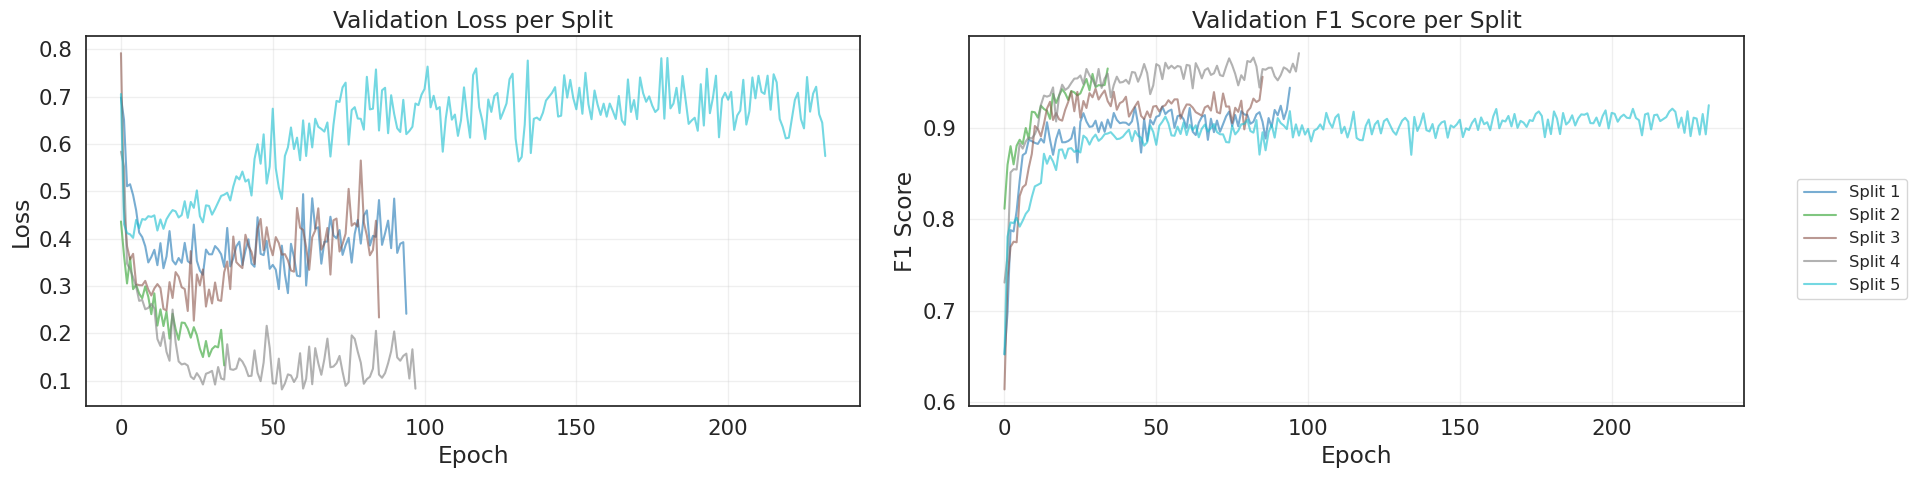

In [ ]:
# @title Plot Hitory
# Create figure with two subplots sharing x axis
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 5), sharex=True)

# Color palette for K splits
colors = plt.cm.get_cmap('tab10', K)

# Plot validation loss for each split
for split in range(K):
    axes[0].plot(losses[f'split_{split}'][:-PATIENCE], label=f'Split {split+1}',
                 color=colors(split), alpha=0.6)
axes[0].set_title('Validation Loss per Split')
axes[0].set_ylabel('Loss')
axes[0].set_xlabel('Epoch')
axes[0].grid(alpha=0.3)

# Plot validation F1 score for each split
for split in range(K):
    axes[1].plot(metrics[f'split_{split}'][:-PATIENCE], label=f'Split {split+1}',
                 color=colors(split), alpha=0.6)
axes[1].set_title('Validation F1 Score per Split')
axes[1].set_ylabel('F1 Score')
axes[1].set_xlabel('Epoch')
axes[1].grid(alpha=0.3)

# Add shared legend on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(right=0.975)
plt.show()

##**Grid Search (with K-Shuffle CV)**

In [34]:
def grid_search_cv_rnn(df, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for RNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_rnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}±{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2='
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}'])
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(μ={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

In [38]:
# Define parameters to search
param_grid = {
    'dropout_rate': [0.5, 0.6],
    'hidden_size': [32, 64]
}

# Fixed hyperparameters (not being tuned)
fixed_params = {
    'window_size': WINDOW_SIZE,
    'stride': STRIDE,
    'batch_size': BATCH_SIZE,
    'l1_lambda': L1_LAMBDA,
    'bidirectional': False,
    'l2_lambda': 1e-4,
    'learning_rate': LEARNING_RATE,
    'rnn_type': 'LSTM',
    'hidden_layers': 4,
}

# Cross-validation settings
cv_params = {
    'epochs': EPOCHS,
    'criterion': criterion,
    'device': device,
    'k': K,
    'n_val_users': N_VAL_USERS,
    'patience': PATIENCE,
    'verbose': 20,
    'seed': SEED
}

# Execute search
results, best_config, best_score = grid_search_cv_rnn(
    df=X_train_mod,
    param_grid=param_grid,
    fixed_params=fixed_params,
    cv_params=cv_params
)


Configuration 1/4:
  dropout_rate: 0.5
  hidden_size: 32
Split 1/5
  Training set shape: (93760, 40)
  Validation set shape: (12000, 40)
  Training sequences shape: (19338, 20, 37)
  Validation sequences shape: (2475, 20, 37)
Training 500 epochs...
Epoch   1/500 | Train: Loss=0.7241, F1 Score=0.6735 | Val: Loss=0.7357, F1 Score=0.6384
Epoch  20/500 | Train: Loss=0.1729, F1 Score=0.9404 | Val: Loss=0.4294, F1 Score=0.8822
Epoch  40/500 | Train: Loss=0.1118, F1 Score=0.9616 | Val: Loss=0.3725, F1 Score=0.9072
Epoch  60/500 | Train: Loss=0.0835, F1 Score=0.9707 | Val: Loss=0.4537, F1 Score=0.9062
Epoch  80/500 | Train: Loss=0.0770, F1 Score=0.9718 | Val: Loss=0.4561, F1 Score=0.9062
Early stopping triggered after 99 epochs.
Best model restored from epoch 29 with val_f1 0.9269
Split 2/5
  Training set shape: (93760, 40)
  Validation set shape: (12000, 40)
  Training sequences shape: (19338, 20, 37)
  Validation sequences shape: (2475, 20, 37)
Training 500 epochs...
Epoch   1/500 | Train: 

In [ ]:
# Visualise results
plot_top_configurations_rnn(results, k_splits=K, top_n=5)

##**Error Visualization per subsequence**

In [ ]:
from math import floor

# REMINDER:
WINDOW_SIZE = 20
STRIDE = 5
BATCH_SIZE = 128
N_VAL_USERS = 75


def study_subsequence(n_subsequence, X_val, y_val, model):

  padding_len = WINDOW_SIZE - 160 % WINDOW_SIZE
  padded_len = 160 + padding_len
  total_subsequences = floor((padded_len - WINDOW_SIZE) / STRIDE) + 1
  total_subsequences = int(total_subsequences)

  N_VAL_USERS = X_val.shape[0]/total_subsequences
  N_VAL_USERS = int(N_VAL_USERS)

  n_sub_backwards = total_subsequences + 1 - n_subsequence

  # Calculate the indices of the last sequence for each validation set element
  last_sequence_indices = [(i * total_subsequences) - n_sub_backwards for i in range(1, N_VAL_USERS + 1)]

  filling = BATCH_SIZE - N_VAL_USERS % BATCH_SIZE
  last_sequence_indices_filler = [i for i in range(0, filling)]
  last_sequence_indices = last_sequence_indices + last_sequence_indices_filler

  # Extract the last sequences from X_val using the calculated indices
  X_val_last_sequence = X_val[last_sequence_indices, :, :]
  y_val_last_sequence  = y_val[last_sequence_indices]

  val_ds   = TensorDataset(torch.from_numpy(X_val_last_sequence), torch.from_numpy(y_val_last_sequence))
  val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

  val_preds, val_targets = [], []
  with torch.no_grad():  # Disable gradient computation for inference
        for xb, yb in val_loader:
          xb = xb.to(device)

          # Forward pass: get model predictions
          logits = model(xb)
          preds = logits.argmax(dim=1).cpu().numpy()

          # Store batch results
          val_preds.append(preds)
          val_targets.append(yb.numpy())


  val_preds = np.concatenate(val_preds)
  val_targets = np.concatenate(val_targets)
  val_preds = val_preds[0:N_VAL_USERS]
  val_targets = val_targets[0:N_VAL_USERS]

  return val_preds, val_targets

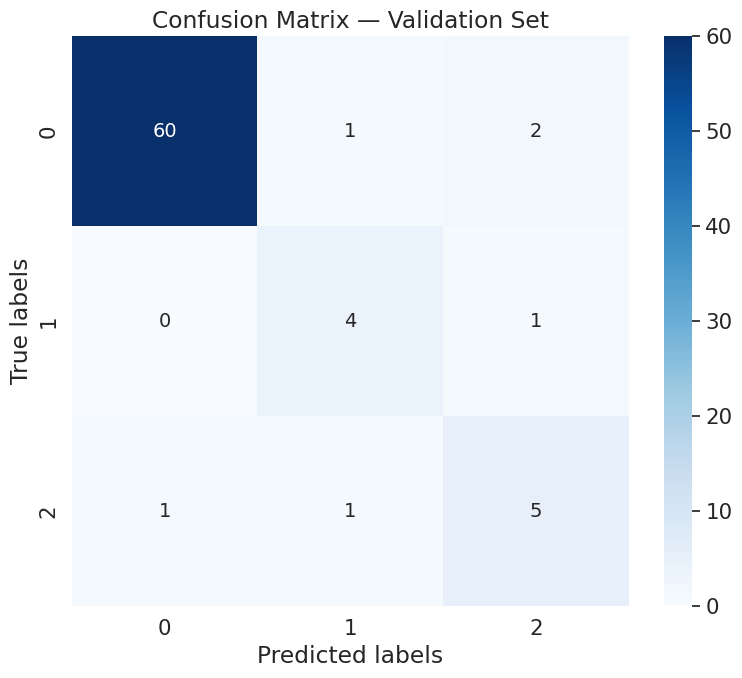

In [ ]:
val_preds, val_targets = study_subsequence(16, X_val, y_val, rnn_model) #input should be a number from 1 to 33

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

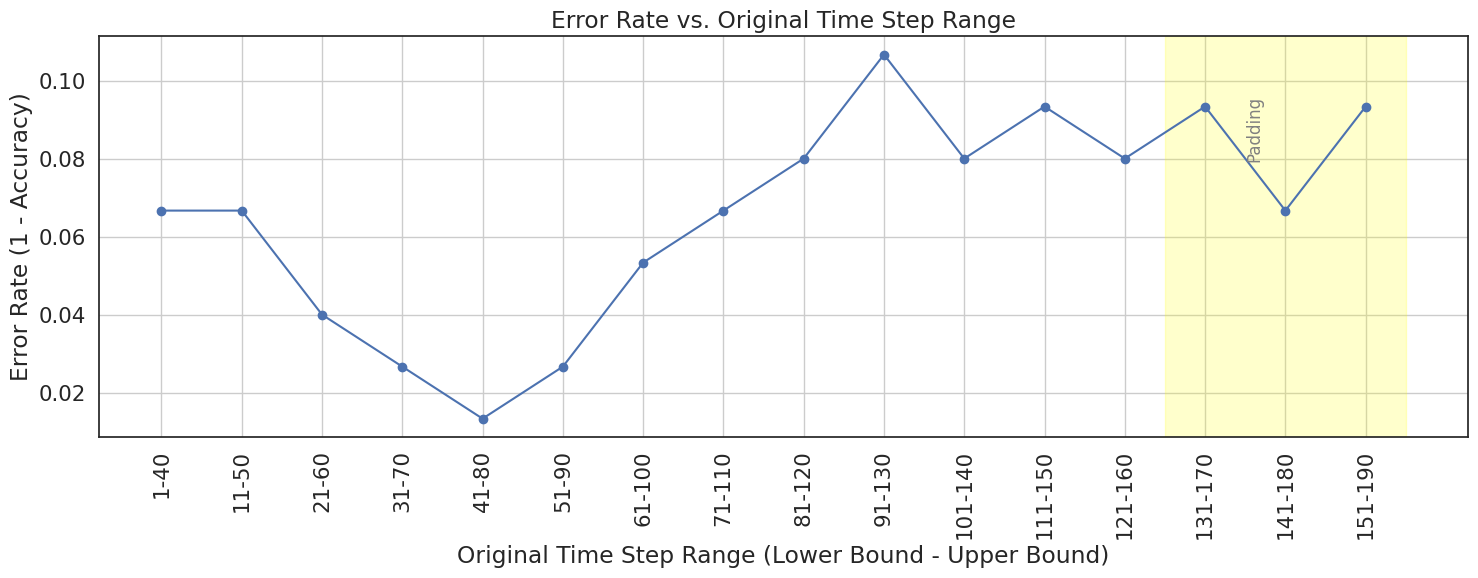

In [ ]:
from sklearn.metrics import accuracy_score

err = []
lower_bounds = []
upper_bounds = []
x_labels = [] # List to store custom x-axis labels

# Assuming WINDOW_SIZE and STRIDE are defined in a previous cell
# WINDOW_SIZE = 20
# STRIDE = 5

num_windows = int(floor(160 / STRIDE))

for i in range(num_windows):
    # Call study_subsequence with 1-based index as it expects
    preds, targets = study_subsequence(i+1, X_val, y_val, rnn_model)

    # Calculate accuracy and then error (1 - accuracy)
    error = 1 - accuracy_score(targets, preds)
    err.append(error)

    # Calculate lower and upper bounds for the original time steps (0-indexed)
    lower_bound = i * STRIDE + 1
    upper_bound = lower_bound + WINDOW_SIZE - 1

    lower_bounds.append(lower_bound)
    upper_bounds.append(upper_bound)

    # Create a string label for the x-axis
    x_labels.append(f"{lower_bound}-{upper_bound}")


# Plot the errors
plt.figure(figsize=(15, 6)) # Increased figure size for better label readability
plt.plot(range(num_windows), err, marker='o', linestyle='-') # Plot against 0-indexed subsequence number

plt.xlabel('Original Time Step Range (Lower Bound - Upper Bound)')
plt.ylabel('Error Rate (1 - Accuracy)')
plt.title('Error Rate vs. Original Time Step Range')

# Set custom x-axis ticks and labels
plt.xticks(range(num_windows), x_labels, rotation=90) # Use x_labels for ticks, rotate for readability

plt.grid(True)

# Find the index where the upper bound first exceeds 160 (length of original data)
padding_start_index = -1
for i, ub in enumerate(upper_bounds):
    if ub > 160:
        padding_start_index = i
        break

# If padding exists, add a shaded region and annotation
if padding_start_index != -1:
    # Shade the area from the start of padding subsequences to the end
    plt.axvspan(padding_start_index - 0.5, len(err) - 0.5, color='yellow', alpha=0.2, label='Padding Region')

    # Add "padding" annotation
    # Position the text near the start of the shaded region
    plt.text(padding_start_index + 0.5, max(err) * 0.9, 'Padding',
             fontsize=12, color='gray', rotation=90, verticalalignment='top')


plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

#**TESTING**

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import os
import torch.nn as nn
from torchsummary import summary as recurrent_summary
import sys
import random

In [ ]:
# here i load data from test_data
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/CHALLENGE1ANN"
%cd $current_dir

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/.shortcut-targets-by-id/1zXlKtIs_l7uErhQ5LyiPQwfRNFrTdsfW/CHALLENGE1ANN


In [ ]:
#Just to make this part of the notebook a little bit more independent from the rest of it, we reimport the datasets and we reprocesse them
#(as we did at the beginning of this notebook)

X_train = pd.read_csv('pirate_pain_train.csv')
y_train = pd.read_csv('pirate_pain_train_labels.csv')

N_VAL_USERS = 75

X_train = X_train.drop('joint_30', axis=1)
for i in range(30):
    col_name = f'joint_{i:02d}' # Formatting the column name (es. 'joint_00', 'joint_01')
    if col_name in X_train.columns:
        X_train[col_name] = X_train[col_name].astype(np.float32)

# Define a mapping of n_legs values to integer labels
label_mapping_legs = {
    'two': 0,
    'one+peg_leg': 1,
}
# Map n_legs attributes to integers in the training set
X_train['n_legs'] = X_train['n_legs'].map(label_mapping_legs)


# Define a mapping of n_hands values to integer labels
label_mapping_hands = {
    'two': 0,
    'one+hook_hand': 1,
}
# Map n_hands attributes to integers in the training set
X_train['n_hands'] = X_train['n_hands'].map(label_mapping_hands)


# Define a mapping of n_eyes values to integer labels
label_mapping_eyes = {
    'two': 0,
    'one+eye_patch': 1,
}
# Map n_eyes attributes to integers in the training set
X_train['n_eyes'] = X_train['n_eyes'].map(label_mapping_eyes)
y_train_expanded = y_train.loc[y_train.index.repeat(160)].reset_index(drop=True)

X_train_mod = X_train.copy()
X_train_mod['label'] = y_train_expanded['label']

# Get unique user IDs and shuffle them
unique_users = X_train_mod['sample_index'].unique()
random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)

# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:n_train_users + N_VAL_USERS]

# Split the dataset into training, validation, and test sets based on user IDs
df_train = X_train_mod[X_train_mod['sample_index'].isin(train_users)]
df_val = X_train_mod[X_train_mod['sample_index'].isin(val_users)]

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')
training_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1


# Define a mapping of pain values to integer labels
label_mapping_pain = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2,
}

# Map activity pain levels to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping_pain)

# Map activity pain levels to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping_pain)
scale_columns = []
for i in range(30):
    scale_columns.append(f'joint_{i:02d}') # Formatting the column name (es. 'joint_00', 'joint_01')

# Calculate the minimum and maximum values from the training data only
# we normalize with respect to the training set, as we have always done
#this is min-max scaling
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the training set
    df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the validation set
    df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

Training set shape: (93760, 40)
Validation set shape: (12000, 40)


In [ ]:
#Preprocessing

X_test = pd.read_csv('pirate_pain_test.csv')
X_test = X_test.drop('joint_30', axis=1) #joint_30 is equal for all of the observed data
for i in range(30):
    col_name = f'joint_{i:02d}' # Formatting the column name (es. 'joint_00', 'joint_01')
    if col_name in X_test.columns:
        X_test[col_name] = X_test[col_name].astype(np.float32)


# Define a mapping of n_legs values to integer labels
label_mapping_legs = {
    'two': 0,
    'one+peg_leg': 1,
}
# Map n_legs attributes to integers in the training set
X_test['n_legs'] = X_test['n_legs'].map(label_mapping_legs)

# Define a mapping of n_hands values to integer labels
label_mapping_hands = {
    'two': 0,
    'one+hook_hand': 1,
}
# Map n_hands attributes to integers in the training set
X_test['n_hands'] = X_test['n_hands'].map(label_mapping_hands)

# Define a mapping of n_eyes values to integer labels
label_mapping_eyes = {
    'two': 0,
    'one+eye_patch': 1,
}
# Map n_eyes attributes to integers in the training set
X_test['n_eyes'] = X_test['n_eyes'].map(label_mapping_eyes)


#Get unique ids
unique_users = X_test['sample_index'].unique()

# Define the columns to be normalised

# Calculate the minimum and maximum values from the training data only
# we normalize with respect to the training set, as we have always done
#this is min-max scaling

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the test set
    X_test[column] = (X_test[column] - mins[column]) / (maxs[column] - mins[column])

X_test.describe()



,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_20,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29
count,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000,...,211840.000000,211840.000000,2.118400e+05,211840.000000,2.118400e+05,211840.000000,211840.000000,211840.000000,211840.000000,211840.000000
mean,661.500000,79.500000,1.615384,1.665625,1.657501,1.663293,0.009819,0.009819,0.009819,0.698955,...,0.000341,0.000022,1.802190e-05,0.000151,9.353109e-04,0.000113,0.032958,0.050642,0.037173,0.044660
std,382.206671,46.187228,0.703560,0.659999,0.666037,0.662678,0.098602,0.098602,0.098602,0.145415,...,0.007169,0.001015,3.165550e-04,0.002030,1.724358e-02,0.001269,0.046782,0.065755,0.041569,0.048622
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000008,0.000002,9.862443e-07,0.000000,-2.918261e-07,0.000000,-0.000166,0.003769,0.002891,0.000000
25%,330.750000,39.750000,1.000000,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.616477,...,0.000023,0.000002,2.249120e-06,0.000002,6.090782e-06,0.000000,0.008732,0.014633,0.014389,0.015325
50%,661.500000,79.500000,2.000000,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.739314,...,0.000029,0.000003,2.749351e-06,0.000009,5.627024e-05,0.000007,0.017936,0.028058,0.025023,0.028229
75%,992.250000,119.250000,2.000000,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.801482,...,0.000042,0.000004,4.342841e-06,0.000017,1.015119e-04,0.000015,0.038024,0.058804,0.043438,0.056676
max,1323.000000,159.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,1.065607,...,1.311883,0.270356,4.810774e-02,0.236165,3.430948e+00,0.176616,1.061880,1.158728,1.000424,0.973029


In [ ]:
# The RecurrentClassifier class is moved here for self-containment.
from math import floor
import os

class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            hidden_size_classifier,
            num_layers,
            num_classes,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        dropout_val = dropout_rate if num_layers > 1 else 0

        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        if self.bidirectional:
            classifier_input_size = hidden_size * 2
        else:
            classifier_input_size = hidden_size

        self.classifier = nn.Sequential(
            nn.Linear(classifier_input_size, hidden_size_classifier),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size_classifier, num_classes)
        )

    def forward(self, x):
        x = x.to(torch.float32)
        rnn_out, hidden = self.rnn(x)

        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        if self.bidirectional:
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            hidden_to_classify = hidden[-1]

        logits = self.classifier(hidden_to_classify)
        return logits

# Funzione per creare i DataLoader, spostata qui per self-containment
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determina il numero ottimale di processi worker per il caricamento dei dati
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Crea DataLoader con ottimizzazioni delle prestazioni
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Trasferimento più rapido alla GPU
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Carica 4 batch in anticipo
    )


# Feature columns definition
feature_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

# input_size for the model
input_size = len(feature_columns)

# Generating all the subsequences of X_test using build_sequences_test
# X_test has been already preprocessed in the previous cells

print("Generating all the subsequences of X_test...")
X_test_all_windowed = build_sequences_test(X_test, window=WINDOW_SIZE, stride=STRIDE)

# converting in numpy array
X_test_all_windowed = np.array(X_test_all_windowed)

print(f"Total number of subsequences generated for the dataset: {X_test_all_windowed.shape[0]}")
print(f"Shape of a subsequence: {X_test_all_windowed.shape[1:]}")

# Create the dataloader for all the subsequences
all_sequences_ds = TensorDataset(torch.from_numpy(X_test_all_windowed))
all_sequences_loader = make_loader(
  all_sequences_ds,
  batch_size=BATCH_SIZE,
  shuffle=False,
  drop_last=False
)

# Predictions on all the subsequences
print("Executing predictions on all the subsequences...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Architecture Parameters (to load the already trained model)
HIDDEN_LAYERS = 2
HIDDEN_SIZE = 128
DROPOUT_RATE = 0.4
HIDDEN_SIZE_CLASSIFIER = 8
num_classes = 3
BIDIRECTIONAL = False
RNN_TYPE = 'LSTM'

# Create an instance of the model
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size=HIDDEN_SIZE,
    hidden_size_classifier = HIDDEN_SIZE_CLASSIFIER,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=False,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Load the trained model
model_path = 'models/lstm_augmented_CONSEGNA.pt'

try:
    rnn_model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Stato del modello caricato con successo da '{model_path}'.")
except FileNotFoundError:
    print(f"Errore: '{model_path}' non trovato. Assicurati che il file del modello sia nella posizione corretta.")
    exit()
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento dello stato del modello: {e}")
    exit()

rnn_model.eval() # Model in evaluation mode

all_flat_predictions = []
with torch.no_grad():
    for inputs in all_sequences_loader:
        inputs = inputs[0].to(device)
        outputs = rnn_model(inputs)
        _, predicted_classes = torch.max(outputs, 1)
        all_flat_predictions.extend(predicted_classes.cpu().numpy().tolist())

all_flat_predictions = np.array(all_flat_predictions)

# Defining the selected subsequences pfor Majority Voting and Tie-breaking ---
# Each subsequence MUST have length equale to WINDOW_SIZE.
# start_timestep - 1 must be a multiple of STRIDE (10).
subsequences_for_voting = [
    (51, 80),
    (61, 90),
    (71, 100),
    (81, 110)

]

#Defining the preferential subsequence in case of a tie
preferential_subsequence = (61, 90)

# Get unique sample indices from the test set
unique_users = X_test['sample_index'].unique()
original_sample_len = 160

#Calculate the number of subsequences generated in the test for each sample
padding_len_per_sample = WINDOW_SIZE - (original_sample_len % WINDOW_SIZE)
if padding_len_per_sample == WINDOW_SIZE:
    padding_len_per_sample = 0
padded_len_per_sample = original_sample_len + padding_len_per_sample
total_subsequences_per_original_sample = int(floor((padded_len_per_sample - WINDOW_SIZE) / STRIDE) + 1)

final_predictions = []
from collections import Counter

print("Applicazione del Majority Voting e Tie-breaking...")
for i, sample_id in enumerate(unique_users):
    # Predictions for the current sample from all the subsequences
    sample_predictions_start_idx = i * total_subsequences_per_original_sample
    sample_predictions_end_idx = sample_predictions_start_idx + total_subsequences_per_original_sample
    current_sample_all_predictions = all_flat_predictions[sample_predictions_start_idx:sample_predictions_end_idx]

    # We store the predictions to use for voting
    votes = []
    for start_ts_1idx, end_ts_1idx in subsequences_for_voting:
        start_ts_0idx = start_ts_1idx - 1
        # Compute the index k of the subsequence relative to the sample
        # This k is the index of the subsequence in 'total_subsequences_per_original_sample'
        relative_subsequence_k = start_ts_0idx // STRIDE

        if relative_subsequence_k < len(current_sample_all_predictions):
            votes.append(current_sample_all_predictions[relative_subsequence_k])
        else:
            # This case shouldn't happen if the subsequences are correctly defined
            print(f"Attenzione: Sottosequenza di voting (start_ts={start_ts_1idx}) fuori dai limiti per sample_id {sample_id}.")

    # Count the votes for each class
    vote_counts = Counter(votes)

    # Find the maximum of the votes
    max_votes = 0
    if vote_counts:
        max_votes = max(vote_counts.values())

    # Classes with the max number of votes
    majority_classes = [cls for cls, count in vote_counts.items() if count == max_votes]

    if len(majority_classes) == 1:
        # No tie, we choose the most voted for class
        final_predictions.append(majority_classes[0])
    else:
        # Ther is a tie: we use the prediction of the preferential subsequence
        pref_start_ts_1idx, _ = preferential_subsequence
        pref_start_ts_0idx = pref_start_ts_1idx - 1
        relative_pref_subsequence_k = pref_start_ts_0idx // STRIDE

        if relative_pref_subsequence_k < len(current_sample_all_predictions):
            final_predictions.append(current_sample_all_predictions[relative_pref_subsequence_k])
        else:
            print(f"Attenzione: Sottosequenza preferenziale (start_ts={pref_start_ts_1idx}) fuori dai limiti per sample_id {sample_id}.")
            final_predictions.append(majority_classes[0] if majority_classes else 0) # Default at 0 (no_pain) if there are no valid votes


# Generating the submission file

pain_level_mapping = {
    0: "no_pain",
    1: "low_pain",
    2: "high_pain"
}

# Map the predictions into pain levels
pain_levels = [pain_level_mapping[pred] for pred in final_predictions]

# Create a dataframe for the submission
submission_df = pd.DataFrame({
    'sample_index': unique_users,
    'label': pain_levels
})

# Name of the sumbmission file
submission_filename = 'ale_augmented.csv'

# Save the dataframe in a csv format
submission_df.to_csv(submission_filename, index=False)

print(f"File di submission '{submission_filename}' creato con successo.")
display(submission_df.head())

Generazione di tutte le sottosequenze da X_test...
Numero totale di sottosequenze generate per tutti i campioni: 21184
Shape di una sottosequenza: (30, 37)
Esecuzione delle predizioni su tutte le sottosequenze...
-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 30, 128], [2, -1, 128]] 217,600        
classifier (Sequential)   [-1, 3]                      1,059          
Total params: 218,659
Trainable params: 218,659
Non-trainable params: 0
-------------------------------------------------------------------------------
Stato del modello caricato con successo da 'models/DARIOPENNONE_model.pt'.
Applicazione del Majority Voting e Tie-breaking...
File di submission 'DARIOAIUTACITU.csv' creato con successo.


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,no_pain
3,3,no_pain
4,4,no_pain
